# Missing-value imputation

## 1. Data treatment

All candidates share the following preprocessing rules before statistical imputation.

| Condition | Treatment |
|---|---|
| Invalid value | Convert to missing |
| Insufficient history | Zero placeholder and indicator |
| Recoverable historical mean | Observed historical spending / prior purchase count |
| Recoverable recency | Interval since the latest earlier training purchase |

The latest available earlier training purchase is assumed to be the true previous purchase. Missingness, recovery and insufficient-history indicators are retained.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if not (root / 'config.yaml').exists():
    root = root.parent
results = root / 'results/imputation_selection'
audit = pd.read_csv(results / 'missingness_audit.csv')
columns = ['prior_mean_gap_days', 'prior_mean_purchase_value', 'days_since_previous_purchase', 'spend_365d', 'payment_type']
display(audit.set_index('column').loc[columns, ['raw_missing', 'structural_missing', 'remaining_after_rules']].rename(columns={
    'raw_missing': 'Original missing', 'structural_missing': 'Insufficient history',
    'remaining_after_rules': 'Remaining gaps'}))

,Original missing,Insufficient history,Remaining gaps
column,,,
prior_mean_gap_days,1174,1001,186
prior_mean_purchase_value,756,578,0
days_since_previous_purchase,745,578,1
spend_365d,169,30,165
payment_type,174,0,174


## 2. Candidate comparison

Five candidates: median + Unknown, median + mode, KNN (5 or 10 neighbours, uniform weights) + Unknown, and iterative + Unknown.

The iterative candidate uses `IterativeImputer` with **BayesianRidge**, `max_iter=10`, `sample_posterior=False` and seed 42. KNN and iterative inputs are scaled with `RobustScaler`.

Evaluation uses 2020–2023 temporal folds, three-year training windows and a 90-day embargo. Fixed models: logistic regression/random forest for classification; Ridge/random forest for conditional spending. Scores are averaged equally across each task's two models and four folds. All preprocessing is fitted within training folds; 2024 remains reserved.

,Mean F1,Mean MAE (EUR)
candidate,,
Median + Unknown,0.7154,1438.55
Median + mode,0.7186,1438.17
KNN (5) + Unknown,0.7151,1440.31
KNN (10) + Unknown,0.7188,1437.89
Iterative (BayesianRidge) + Unknown,0.7170,1440.02


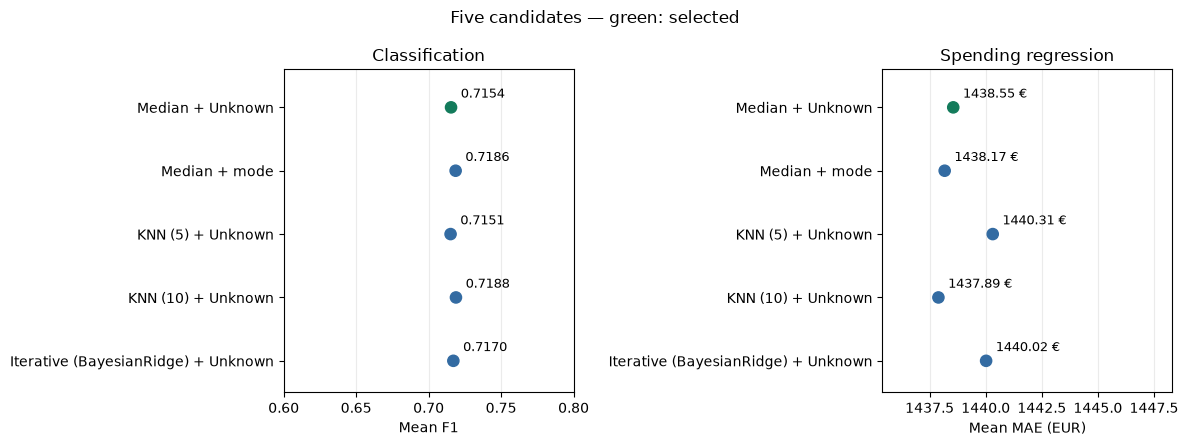

In [2]:
summary = pd.read_csv(results / 'selection_summary.csv')
selected = json.loads((results / 'selected.json').read_text())
labels = {
    'median_0_uniform__unknown': 'Median + Unknown',
    'median_0_uniform__mode': 'Median + mode',
    'knn_5_uniform__unknown': 'KNN (5) + Unknown',
    'knn_10_uniform__unknown': 'KNN (10) + Unknown',
    'iterative_0_uniform__unknown': 'Iterative (BayesianRidge) + Unknown',
}
table = summary.pivot(index='candidate', columns='task', values='mean').reindex(labels)
table.columns = ['Mean F1', 'Mean MAE (EUR)']
table.index = table.index.map(labels)
display(table.round({'Mean F1': 4, 'Mean MAE (EUR)': 2}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, task, column in zip(axes, ['classification', 'regression'], table.columns):
    values = table[column].to_numpy()
    chosen_label = labels[selected[task]['candidate']]
    colors = ['#137b5b' if label == chosen_label else '#336ba2' for label in table.index]
    ax.scatter(values, range(len(values)), c=colors, s=65, zorder=3)
    ax.set_yticks(range(len(values)), table.index)
    ax.set_ylim(len(values) - 0.5, -0.6)
    ax.set_xlabel(column)
    ax.set_title('Classification' if task == 'classification' else 'Spending regression')
    ax.grid(axis='x', alpha=0.25)
    if task == 'classification':
        ax.set_xlim(0.6, 0.8)
    else:
        span = max(values.max() - values.min(), 10)
        ax.set_xlim(values.min() - span * 0.25, values.max() + span * 0.8)
    for i, value in enumerate(values):
        ax.annotate(f'{value:.4f}' if task == 'classification' else f'{value:.2f} €',
                    (value, i), xytext=(7, 7), textcoords='offset points', fontsize=9)
fig.suptitle('Five candidates — green: selected', fontsize=12)
fig.tight_layout()
fig.savefig(results / 'method_comparison.png', dpi=150)
plt.show()

## 3. Selection

Prefer the simplest candidate within **0.005 F1** of the classification best or **1% MAE** of the regression best. Simplicity order: median, KNN, iterative; Unknown before mode. These are practical selection tolerances.

In [3]:
rows = []
for task, title in [('classification', 'Classification'), ('regression', 'Regression')]:
    part = summary[summary.task.eq(task)]
    best = part.loc[part['mean'].idxmax() if task == 'classification' else part['mean'].idxmin()]
    chosen = part[part.candidate.eq(selected[task]['candidate'])].iloc[0]
    difference = best['mean'] - chosen['mean'] if task == 'classification' else 100 * (chosen['mean'] / best['mean'] - 1)
    rows.append({'Task': title, 'Best-scoring candidate': labels[best.candidate],
                 'Selected candidate': labels[chosen.candidate],
                 'Gap to best': f'{difference:.4f} F1' if task == 'classification' else f'{difference:.2f}% MAE',
                 'Within tolerance?': 'Yes' if bool(chosen.eligible) else 'No'})
display(pd.DataFrame(rows).set_index('Task'))

,Best-scoring candidate,Selected candidate,Gap to best,Within tolerance?
Task,,,,
Classification,KNN (10) + Unknown,Median + Unknown,0.0034 F1,Yes
Regression,KNN (10) + Unknown,Median + Unknown,0.05% MAE,Yes


## 4. Combined prediction

At threshold 0.5, predicted nonreturners receive zero spending; predicted returners receive the conditional regression estimate. The regressor is trained on returners with observed spending.

The table reports mean fold MAE for the combined system. Actual nonreturners have zero spending; returners with unknown spending are excluded from monetary evaluation.

In [4]:
end = pd.read_csv(results / 'end_to_end.csv')
combined = end.groupby(['classifier', 'regressor'])['mae'].mean().round(2).reset_index()
combined.columns = ['Classifier', 'Regressor', 'System MAE (EUR)']
combined = combined.replace({'logistic_regression': 'Logistic regression', 'random_forest': 'Random forest', 'ridge': 'Ridge'})
display(combined)

,Classifier,Regressor,System MAE (EUR)
0,Logistic regression,Random forest,1004.73
1,Logistic regression,Ridge,1020.94
2,Random forest,Random forest,1047.98
3,Random forest,Ridge,1037.78


## 5. Conclusion

**Median + Unknown** is selected for both tasks after structural handling and recovery. Alternative gains fall within the declared tolerances. The selection is configured in `config.yaml`; final model performance remains to be assessed on the holdout.

## 6. Sensitivity to numerical reference columns

Compare the original eight inputs with all eligible numerical predictors. Both variants fill the same four columns after the existing cleaning and recovery rules. Models, categorical imputation and temporal folds match the original comparison. Median + Unknown is included as the baseline.

In [5]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import f1_score, mean_absolute_error

project = Path.cwd()
if not (project / 'config.yaml').exists():
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from src.data_loader import load_config
from src.imputation import (
    ImputationPreprocessor, candidate_config, candidates, encode, estimators, regression_mask,
)
from src.preprocessing import prepare_rows
from src.validation import temporal_cv

config = load_config()
validation = config['validation']
raw = pd.read_csv(project / config['paths']['train'])
years = pd.to_datetime(raw['purchase_date'], errors='coerce').dt.year
dev = prepare_rows(raw.loc[years.le(max(validation['cv_years']))], config)
folds = temporal_cv(
    dev, validation['cv_years'], validation['target_horizon_days'],
    strategy=validation['strategy'], train_years=validation['sliding_window']['train_years'],
)
methods = [candidate for candidate in candidates(config) if candidate['categorical'] == 'unknown']
classification_target = config['columns']['classification_target']
regression_target = config['columns']['regression_target']
records, convergence_warnings = [], []
for year, train, val in folds:
    numeric_columns = ImputationPreprocessor(config).fit(train).numeric_
    for candidate in methods:
        input_sets = ['Not applicable'] if candidate['numeric'] == 'median' else ['Original', 'All numerical']
        for inputs in input_sets:
            cfg = candidate_config(config, candidate)
            if inputs == 'All numerical':
                cfg['preprocessing']['numeric_imputation']['knn']['reference_columns'] = numeric_columns
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always', ConvergenceWarning)
                fitted = ImputationPreprocessor(cfg).fit(train)
            if any(issubclass(w.category, ConvergenceWarning) for w in caught):
                convergence_warnings.append((year, candidate['label'], inputs))
            X_train, X_val, _, _ = encode(fitted, train, val, cfg)
            input_count = len(fitted.multivariate_columns_) if fitted.imputer_ is not None else 0

            for task, task_models in estimators(cfg).items():
                if task == 'classification':
                    target = classification_target
                    train_mask, val_mask = train[target].isin([0, 1]), val[target].isin([0, 1])
                else:
                    target = regression_target
                    train_mask, val_mask = regression_mask(train, cfg), regression_mask(val, cfg)
                for name, model in task_models.items():
                    model.fit(X_train.loc[train_mask], train.loc[train_mask, target])
                    X_eval = X_val.loc[val_mask]
                    truth = val.loc[val_mask, target]
                    if task == 'classification':
                        positive = list(model.classes_).index(1)
                        metrics = {'Mean F1': f1_score(truth, model.predict_proba(X_eval)[:, positive] >= 0.5)}
                    else:
                        prediction = np.maximum(0, model.predict(X_eval))
                        metrics = {'Mean MAE (EUR)': mean_absolute_error(truth, prediction)}
                    records.append({
                        'Method': candidate['label'], 'Inputs': inputs, 'Numeric inputs': input_count,
                        'Fold': year, 'Model': name, **metrics,
                    })

sensitivity_scores = pd.DataFrame(records)
comparison = sensitivity_scores.groupby(['Method', 'Inputs'], sort=False).agg(
    min_inputs=('Numeric inputs', 'min'), max_inputs=('Numeric inputs', 'max'),
    mean_f1=('Mean F1', 'mean'), mean_mae=('Mean MAE (EUR)', 'mean'),
)
comparison['Numeric inputs'] = [
    '—' if low == 0 else str(low) if low == high else f'{low}–{high}'
    for low, high in zip(comparison['min_inputs'], comparison['max_inputs'])
]
display(comparison[['Numeric inputs', 'mean_f1', 'mean_mae']]
        .rename(columns={'mean_f1': 'Mean F1', 'mean_mae': 'Mean MAE (EUR)'})
        .round({'Mean F1': 4, 'Mean MAE (EUR)': 2}))
if convergence_warnings:
    print('Iteration limit reached in:', ', '.join(f'{year} ({inputs})' for year, _, inputs in convergence_warnings))


Numeric inputs  Mean F1  \
Method                              Inputs                                   
Median + Unknown                    Not applicable              —   0.7154   
KNN (k=5) + Unknown                 Original                    8   0.7151   
                                    All numerical              28   0.7162   
KNN (k=10) + Unknown                Original                    8   0.7188   
                                    All numerical              28   0.7143   
Iterative (BayesianRidge) + Unknown Original                    8   0.7170   
                                    All numerical              28   0.7153   

                                                    Mean MAE (EUR)  
Method                              Inputs                          
Median + Unknown                    Not applicable         1438.55  
KNN (k=5) + Unknown                 Original               1440.31  
                                    All numerical          1437.64  
KNN (k=10) + Unknown                Original               1437.89  
                                    All numerical          1441.47  
Iterative (BayesianRidge) + Unknown Original               1440.02  
                                    All numerical          1438.93

Using all 28 numerical inputs slightly improves KNN (k=5) on both metrics, worsens KNN (k=10) on both, and gives mixed results for iterative imputation. Across the variants in this check, median + Unknown remains within 0.005 F1 and 1% MAE of the best mean scores.

## 7. Customer-history imputation

With median numeric imputation fixed, compare Unknown, the latest known value, and the historical mode for `payment_type`, `warehouse`, and `salesperson`. Both history methods use strictly earlier training purchases, with at least one known value. Mode ties use the most recent tied value. Missing categories without usable history remain Unknown.

The predictive comparison uses real missing values. A separate diagnostic randomly hides 10% of known validation values per feature and fold (seed 42) to measure coverage and accuracy on the entries recovered. Rows without purchase dates are outside this evaluation.

In [6]:
from src.feature_transformer import apply_feature_transformer, fit_feature_transformer

history_settings = config['preprocessing']['categorical_missing']
history_columns = history_settings['recover_from_customer_history']
customer_column = config['columns']['customer_id']
date_column = config['preprocessing']['date_features']['source_column']
fallback = history_settings['fallback_value']


def known_customer_history(train):
    ordered = train.sort_values(date_column, kind='stable')
    return {
        column: {
            customer: (rows[date_column].to_numpy(), rows[column].to_numpy())
            for customer, rows in ordered.dropna(subset=[column, date_column]).groupby(customer_column)
        }
        for column in history_columns
    }


def historical_modes(frame, history):
    recovered = {}
    for column in history_columns:
        estimates = {}
        missing = frame.loc[frame[column].isna(), [customer_column, date_column]].dropna()
        for index, (customer, date) in zip(missing.index, missing.itertuples(index=False, name=None)):
            if customer not in history[column]:
                continue
            dates, values = history[column][customer]
            end = dates.searchsorted(date.to_datetime64(), side='left')
            if end == 0:
                continue
            previous = values[:end]
            counts = pd.Series(previous).value_counts()
            tied = set(counts.index[counts.eq(counts.max())])
            estimates[index] = next(value for value in reversed(previous) if value in tied)
        recovered[column] = pd.Series(estimates, dtype=object)
    return recovered


def apply_customer_modes(prepared, frame, history):
    prepared = prepared.copy()
    for column, estimates in historical_modes(frame, history).items():
        prepared.loc[estimates.index, column] = estimates
        prepared.loc[estimates.index, f'{column}_was_recovered'] = 1
    return prepared


In [7]:
folds = temporal_cv(
    dev, validation['cv_years'], validation['target_horizon_days'],
    strategy=validation['strategy'], train_years=validation['sliding_window']['train_years'],
)
median_candidate = next(candidate for candidate in methods if candidate['numeric'] == 'median')
unknown_config = candidate_config(config, median_candidate)
latest_config = candidate_config(config, {**median_candidate, 'categorical': 'history'})
strategies = {
    'Unknown': unknown_config,
    'Latest customer value': latest_config,
    'Customer mode': unknown_config,
}
rng = np.random.default_rng(42)
prediction_scores, recovery_scores = [], []
for year, train, val in folds:
    history = known_customer_history(train)
    labels = {}
    masked = val.copy()
    for column in history_columns:
        known = val.index[val[column].notna()]
        indexes = rng.choice(known, size=round(len(known) * 0.1), replace=False)
        labels[column] = val.loc[indexes, column]
        masked.loc[indexes, column] = np.nan

    for strategy, cfg in strategies.items():
        fitted = ImputationPreprocessor(cfg).fit(train)
        train_ready, val_ready = fitted.transform(train), fitted.transform(val)
        masked_ready = fitted.transform(masked)
        if strategy == 'Customer mode':
            train_ready = apply_customer_modes(train_ready, train, history)
            val_ready = apply_customer_modes(val_ready, val, history)
            masked_ready = apply_customer_modes(masked_ready, masked, history)

        for column, truth in labels.items():
            recovered = masked_ready.loc[truth.index, f'{column}_was_recovered'].eq(1)
            guesses = masked_ready.loc[truth.index, column]
            recovery_scores.append({
                'Strategy': strategy, 'Feature': column, 'Fold': year,
                'Hidden': len(truth), 'Recovered': recovered.sum(),
                'Correct': (guesses.eq(truth) & recovered).sum(),
                'Real missing': val[column].isna().sum(),
                'Real recovered': val_ready.loc[val[column].isna(), f'{column}_was_recovered'].sum(),
            })

        encoder, columns = fit_feature_transformer(train_ready, cfg)
        X_train = apply_feature_transformer(train_ready, encoder, columns, cfg)
        X_val = apply_feature_transformer(val_ready, encoder, columns, cfg)
        for task, task_models in estimators(cfg).items():
            if task == 'classification':
                target = classification_target
                train_mask, val_mask = train[target].isin([0, 1]), val[target].isin([0, 1])
            else:
                target = regression_target
                train_mask, val_mask = regression_mask(train, cfg), regression_mask(val, cfg)
            truth = val.loc[val_mask, target]
            for name, model in task_models.items():
                model.fit(X_train.loc[train_mask], train.loc[train_mask, target])
                if task == 'classification':
                    positive = list(model.classes_).index(1)
                    probability = model.predict_proba(X_val.loc[val_mask])[:, positive]
                    metric = {'Mean F1': f1_score(truth, probability >= 0.5)}
                else:
                    prediction = np.maximum(0, model.predict(X_val.loc[val_mask]))
                    metric = {'Mean MAE (EUR)': mean_absolute_error(truth, prediction)}
                prediction_scores.append({'Strategy': strategy, 'Fold': year, 'Model': name, **metric})

customer_metrics = (
    pd.DataFrame(prediction_scores).groupby('Strategy', sort=False)[['Mean F1', 'Mean MAE (EUR)']].mean()
)
display(customer_metrics.round({'Mean F1': 4, 'Mean MAE (EUR)': 2}))

recovery = pd.DataFrame(recovery_scores).groupby(['Feature', 'Strategy'], sort=False)[
    ['Hidden', 'Recovered', 'Correct', 'Real missing', 'Real recovered']
].sum()
recovery['Masked coverage (%)'] = 100 * recovery['Recovered'] / recovery['Hidden']
recovery['Accuracy when recovered (%)'] = 100 * recovery['Correct'] / recovery['Recovered'].replace(0, np.nan)
display(recovery[['Real missing', 'Real recovered', 'Hidden', 'Masked coverage (%)',
                  'Accuracy when recovered (%)']].round(1))


,Mean F1,Mean MAE (EUR)
Strategy,,
Unknown,0.7154,1438.55
Latest customer value,0.7182,1439.86
Customer mode,0.7153,1440.97


,,Real missing,Real recovered,Hidden,Masked coverage (%),Accuracy when recovered (%)
Feature,Strategy,,,,,
payment_type,Unknown,94,0,275,0.0,NaN
warehouse,Unknown,88,0,276,0.0,NaN
salesperson,Unknown,80,0,277,0.0,NaN
payment_type,Latest customer value,94,83,275,89.8,97.6
warehouse,Latest customer value,88,69,276,89.5,100.0
salesperson,Latest customer value,80,67,277,85.9,94.5
payment_type,Customer mode,94,83,275,89.8,96.4
warehouse,Customer mode,88,69,276,89.5,100.0
salesperson,Customer mode,80,67,277,85.9,89.9


Both history methods recover 219 of 262 genuine gaps in the three columns. On masked entries with usable history, accuracy is 97.4% for the latest value and 95.5% for the customer mode. Median + Unknown remains the selected strategy because its F1 is within 0.005 of the best result here and it has the lowest MAE. Masked accuracy measures recovery on known values that were hidden for the diagnostic.